# CodeAlpha Internship — Credit Scoring / Credit Default Prediction

**Project goal:** Predict whether a customer is likely to default using financial, spending, debt, savings, credit and household-related information.

**Dataset:** `credit_default_dataset.csv`  
**Rows:** 4,995  
**Columns:** 87  
**Target:** `DEFAULT` — 0 = non-default, 1 = default

This notebook follows a complete ML workflow: data understanding → cleaning → EDA → preprocessing → train/test split → Logistic Regression → Decision Tree → Random Forest → evaluation → model comparison → model saving → example prediction.


In [1]:
# Cell 1 — Import libraries

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
# Cell 2 — Load dataset

DATA_PATH = "../data/credit_default_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)


Dataset loaded successfully.
Shape: (4995, 87)


In [3]:
# Cell 3 — Preview the data

display(df.head())


,CUST_ID,INCOME,SAVINGS,DEBT,R_SAVINGS_INCOME,R_DEBT_INCOME,R_DEBT_SAVINGS,T_CLOTHING_12,T_CLOTHING_6,R_CLOTHING,...,R_EXPENDITURE_SAVINGS,R_EXPENDITURE_DEBT,CAT_GAMBLING,CAT_DEBT,CAT_CREDIT_CARD,CAT_MORTGAGE,CAT_SAVINGS_ACCOUNT,CAT_DEPENDENTS,CREDIT_SCORE,DEFAULT
0,sdv-id-AWJoYv,191494,180225,1139049,1.0078,5.6095,5.0460,10767,820,0.2560,...,0.7498,0.1892,High,1,0,0,1,0,549,0
1,sdv-id-MqZrHS,254424,417046,2352895,0.8015,9.1589,5.5971,8334,5446,0.7503,...,0.8193,0.1196,No,1,1,0,1,1,585,0
2,sdv-id-Evqdpj,289663,1164809,391824,4.2743,1.1205,0.4475,28508,11466,0.5036,...,0.1899,0.6184,High,1,0,1,1,1,606,0
3,sdv-id-CHnYOs,135976,262012,587142,1.5431,5.0954,2.8511,12821,2232,0.1118,...,0.3968,0.2254,No,1,0,0,1,0,662,0
4,sdv-id-ByqsvL,205132,646284,1888055,3.9963,8.3456,2.3779,9073,1526,0.1994,...,0.2813,0.1406,No,1,0,0,1,0,598,0


In [4]:
# Cell 4 — Dataset information

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4995 entries, 0 to 4994
Data columns (total 87 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   CUST_ID                  4995 non-null   str    
 1   INCOME                   4995 non-null   int64  
 2   SAVINGS                  4995 non-null   int64  
 3   DEBT                     4995 non-null   int64  
 4   R_SAVINGS_INCOME         4995 non-null   float64
 5   R_DEBT_INCOME            4995 non-null   float64
 6   R_DEBT_SAVINGS           4995 non-null   float64
 7   T_CLOTHING_12            4995 non-null   int64  
 8   T_CLOTHING_6             4995 non-null   int64  
 9   R_CLOTHING               4995 non-null   float64
 10  R_CLOTHING_INCOME        4995 non-null   float64
 11  R_CLOTHING_SAVINGS       4995 non-null   float64
 12  R_CLOTHING_DEBT          4995 non-null   float64
 13  T_EDUCATION_12           4995 non-null   int64  
 14  T_EDUCATION_6            4995 non-n

In [5]:
# Cell 5 — Column names

print("Number of columns:", len(df.columns))
print("\nColumns:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")


Number of columns: 87

Columns:
01. CUST_ID
02. INCOME
03. SAVINGS
04. DEBT
05. R_SAVINGS_INCOME
06. R_DEBT_INCOME
07. R_DEBT_SAVINGS
08. T_CLOTHING_12
09. T_CLOTHING_6
10. R_CLOTHING
11. R_CLOTHING_INCOME
12. R_CLOTHING_SAVINGS
13. R_CLOTHING_DEBT
14. T_EDUCATION_12
15. T_EDUCATION_6
16. R_EDUCATION
17. R_EDUCATION_INCOME
18. R_EDUCATION_SAVINGS
19. R_EDUCATION_DEBT
20. T_ENTERTAINMENT_12
21. T_ENTERTAINMENT_6
22. R_ENTERTAINMENT
23. R_ENTERTAINMENT_INCOME
24. R_ENTERTAINMENT_SAVINGS
25. R_ENTERTAINMENT_DEBT
26. T_FINES_12
27. T_FINES_6
28. R_FINES
29. R_FINES_INCOME
30. R_FINES_SAVINGS
31. R_FINES_DEBT
32. T_GAMBLING_12
33. T_GAMBLING_6
34. R_GAMBLING
35. R_GAMBLING_INCOME
36. R_GAMBLING_SAVINGS
37. R_GAMBLING_DEBT
38. T_GROCERIES_12
39. T_GROCERIES_6
40. R_GROCERIES
41. R_GROCERIES_INCOME
42. R_GROCERIES_SAVINGS
43. R_GROCERIES_DEBT
44. T_HEALTH_12
45. T_HEALTH_6
46. R_HEALTH
47. R_HEALTH_INCOME
48. R_HEALTH_SAVINGS
49. R_HEALTH_DEBT
50. T_HOUSING_12
51. T_HOUSING_6
52. R_HOUSING
53

In [6]:
# Cell 6 — Missing values and duplicates

missing = df.isnull().sum()
print("Total missing values:", int(missing.sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

if missing.sum() == 0:
    print("No missing values found.")


Total missing values: 0
Duplicate rows: 0
No missing values found.


In [7]:
# Cell 7 — Basic statistics

display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
INCOME,4995.0,112030.816016,121991.815056,0.0000,8950.50000,61229.0000,1.914680e+05,6.620940e+05
SAVINGS,4995.0,418412.768368,438482.995434,0.0000,75752.50000,289112.0000,6.234835e+05,2.911863e+06
DEBT,4995.0,720002.043443,997566.245796,0.0000,19980.50000,227158.0000,1.095794e+06,5.968620e+06
R_SAVINGS_INCOME,4995.0,4.489922,4.382761,0.0000,0.98080,2.9774,6.799900e+00,1.611120e+01
R_DEBT_INCOME,4995.0,6.176271,4.924046,0.0833,2.24625,5.1254,8.986100e+00,3.323510e+01
...,...,...,...,...,...,...,...,...
CAT_MORTGAGE,4995.0,0.180981,0.385041,0.0000,0.00000,0.0000,0.000000e+00,1.000000e+00
CAT_SAVINGS_ACCOUNT,4995.0,0.994194,0.075982,0.0000,1.00000,1.0000,1.000000e+00,1.000000e+00
CAT_DEPENDENTS,4995.0,0.174575,0.379641,0.0000,0.00000,0.0000,0.000000e+00,1.000000e+00
CREDIT_SCORE,4995.0,587.779980,62.274917,300.0000,551.00000,595.0000,6.340000e+02,7.730000e+02


In [8]:
# Cell 8 — Target distribution

target_counts = df["DEFAULT"].value_counts().sort_index()

print("DEFAULT value counts:")
print(target_counts)

print("\nDEFAULT percentages:")
print((df["DEFAULT"].value_counts(normalize=True).sort_index() * 100).round(2))


DEFAULT value counts:
DEFAULT
0    3542
1    1453
Name: count, dtype: int64

DEFAULT percentages:
DEFAULT
0    70.91
1    29.09
Name: proportion, dtype: float64


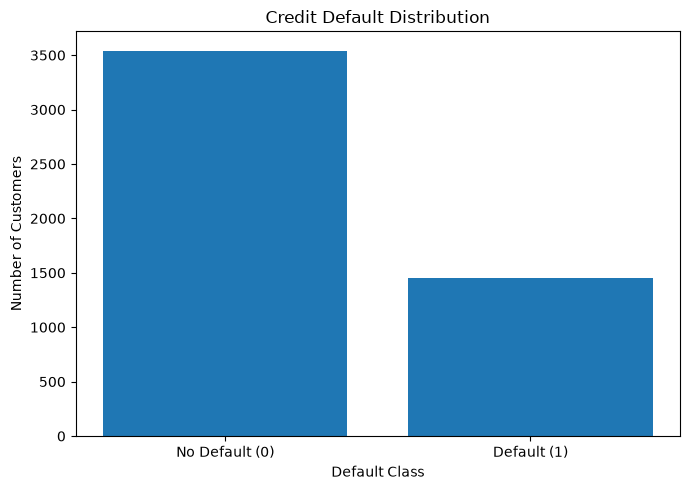

In [9]:
# Cell 9 — Target visualization

counts = df["DEFAULT"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(["No Default (0)", "Default (1)"], counts.values)
plt.title("Credit Default Distribution")
plt.xlabel("Default Class")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [10]:
# Cell 10 — Identify categorical and numerical columns

categorical_columns = df.drop(columns=["DEFAULT"]).select_dtypes(include=["object"]).columns.tolist()
numerical_columns = df.drop(columns=["DEFAULT"]).select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical columns:", categorical_columns)
print("Number of numerical columns:", len(numerical_columns))


Categorical columns: ['CUST_ID', 'CAT_GAMBLING']
Number of numerical columns: 84


In [11]:
# Cell 11 — Inspect categorical values

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))



CUST_ID:
CUST_ID
sdv-id-AWJoYv    1
sdv-id-MqZrHS    1
sdv-id-Evqdpj    1
sdv-id-CHnYOs    1
sdv-id-ByqsvL    1
                ..
sdv-id-cxGJYL    1
sdv-id-XCpOOv    1
sdv-id-VDvfbd    1
sdv-id-tbZbxA    1
sdv-id-oNpjyu    1
Name: count, Length: 4995, dtype: int64

CAT_GAMBLING:
CAT_GAMBLING
No      3098
High    1257
Low      640
Name: count, dtype: int64


In [12]:
# Cell 12 — Remove identifier and constant columns

# CUST_ID is an identifier, not a meaningful predictive feature.
# R_HOUSING has only one unique value in this dataset, so it carries no information.

df_model = df.drop(columns=["CUST_ID", "R_HOUSING"]).copy()

print("Shape after removing non-informative columns:", df_model.shape)


Shape after removing non-informative columns: (4995, 85)


In [13]:
# Cell 13 — Correlation with target

numeric_for_corr = df_model.select_dtypes(include=np.number)

target_correlation = (
    numeric_for_corr.corr()["DEFAULT"]
    .drop("DEFAULT")
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

display(target_correlation.head(15).to_frame("Correlation with DEFAULT"))


,Correlation with DEFAULT
CREDIT_SCORE,-0.189281
R_DEBT_INCOME,0.149413
R_EXPENDITURE_DEBT,-0.132560
R_HEALTH_DEBT,-0.116251
R_UTILITIES_DEBT,-0.110853
R_GROCERIES_DEBT,-0.108948
DEBT,0.099118
R_ENTERTAINMENT_DEBT,-0.091523
R_CLOTHING_DEBT,-0.089405
CAT_CREDIT_CARD,0.088310


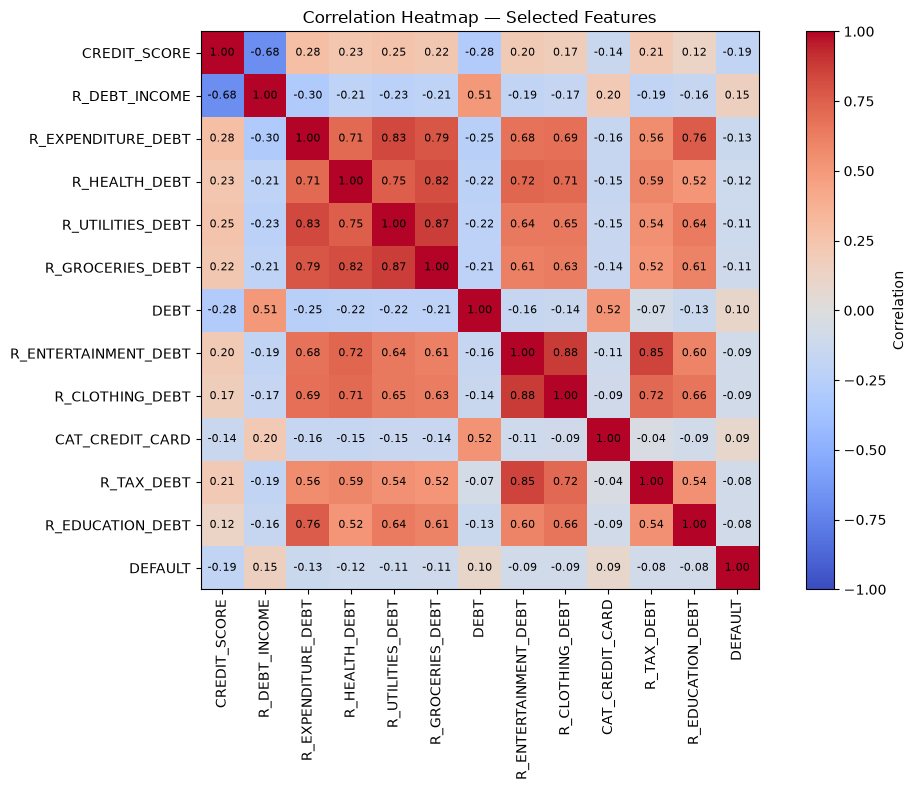

In [14]:
# Cell 14 — Correlation heatmap for selected numerical features

top_corr_features = target_correlation.head(12).index.tolist() + ["DEFAULT"]
corr_matrix = df_model[top_corr_features].corr()

fig, ax = plt.subplots(figsize=(11, 8))
image = ax.imshow(corr_matrix.values, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticklabels(corr_matrix.index)

for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=8)

fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Correlation Heatmap — Selected Features")
plt.tight_layout()
plt.show()


In [15]:
# Cell 15 — Define features and target

X = df_model.drop(columns=["DEFAULT"])
y = df_model["DEFAULT"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (4995, 84)
Target shape: (4995,)


In [16]:
# Cell 16 — Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training default rate:", round(y_train.mean(), 4))
print("Testing default rate:", round(y_test.mean(), 4))


Training rows: 3996
Testing rows: 999
Training default rate: 0.2908
Testing default rate: 0.2913


In [17]:
# Cell 17 — Build preprocessing pipelines

categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X_train.select_dtypes(exclude=["object"]).columns.tolist()

# Logistic Regression: median imputation + standard scaling for numeric data.
# One-hot encoding is used for categorical data.
scaled_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

# Tree models do not require feature scaling.
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numerical_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

print("Preprocessing pipelines created.")
print("Categorical features:", categorical_features)
print("Numerical features:", len(numerical_features))


Preprocessing pipelines created.
Categorical features: ['CAT_GAMBLING']
Numerical features: 83


In [18]:
# Cell 18 — Logistic Regression

logistic_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression trained successfully.")


Logistic Regression trained successfully.


In [19]:
# Cell 19 — Decision Tree

decision_tree_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

tree_pred = decision_tree_model.predict(X_test)
tree_prob = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree trained successfully.")


Decision Tree trained successfully.


In [20]:
# Cell 20 — Random Forest

random_forest_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

forest_pred = random_forest_model.predict(X_test)
forest_prob = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest trained successfully.")


Random Forest trained successfully.


In [21]:
# Cell 21 — Evaluation function

def evaluate_model(model_name, y_true, predictions, probabilities):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }


In [22]:
# Cell 22 — Evaluate all models

results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, logistic_pred, logistic_prob),
    evaluate_model("Decision Tree", y_test, tree_pred, tree_prob),
    evaluate_model("Random Forest", y_test, forest_pred, forest_prob)
])

results = results.sort_values(
    by=["F1-Score", "ROC-AUC"],
    ascending=False
).reset_index(drop=True)

display(results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.6507,0.4350,0.6667,0.5265,0.7071
1,Decision Tree,0.5826,0.3698,0.6151,0.4619,0.5933
2,Random Forest,0.6697,0.4253,0.3814,0.4022,0.6614


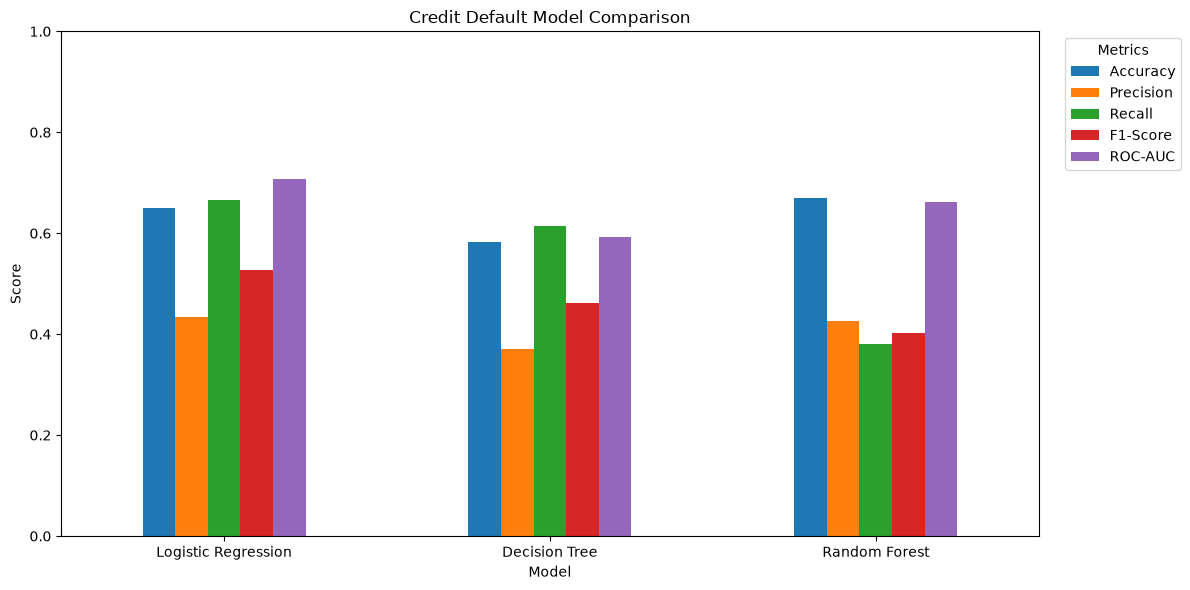

In [23]:
# Cell 23 — Model comparison chart

plot_results = results.set_index("Model")

plot_results.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Credit Default Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [24]:
# Cell 24 — Classification reports

print("LOGISTIC REGRESSION")
print(classification_report(y_test, logistic_pred, zero_division=0))

print("\nDECISION TREE")
print(classification_report(y_test, tree_pred, zero_division=0))

print("\nRANDOM FOREST")
print(classification_report(y_test, forest_pred, zero_division=0))


LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.82      0.64      0.72       708
           1       0.43      0.67      0.53       291

    accuracy                           0.65       999
   macro avg       0.63      0.66      0.62       999
weighted avg       0.71      0.65      0.67       999


DECISION TREE
              precision    recall  f1-score   support

           0       0.78      0.57      0.66       708
           1       0.37      0.62      0.46       291

    accuracy                           0.58       999
   macro avg       0.58      0.59      0.56       999
weighted avg       0.66      0.58      0.60       999


RANDOM FOREST
              precision    recall  f1-score   support

           0       0.76      0.79      0.77       708
           1       0.43      0.38      0.40       291

    accuracy                           0.67       999
   macro avg       0.59      0.58      0.59       999
weighted avg       0.66 

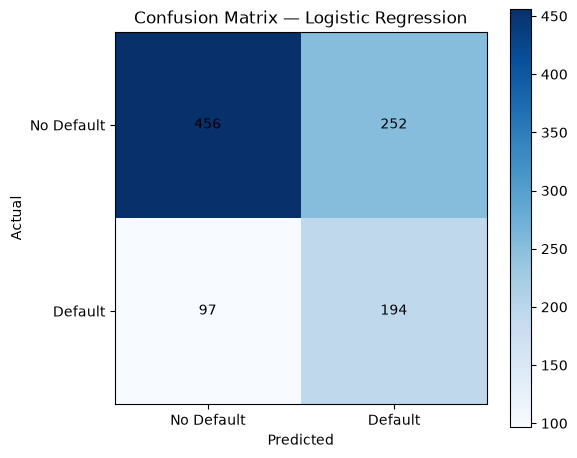

Selected model: Logistic Regression


In [25]:
# Cell 25 — Confusion matrix for the best model

best_model_name = results.iloc[0]["Model"]

prediction_map = {
    "Logistic Regression": logistic_pred,
    "Decision Tree": tree_pred,
    "Random Forest": forest_pred
}

best_predictions = prediction_map[best_model_name]
cm = confusion_matrix(y_test, best_predictions)

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["No Default", "Default"])
ax.set_yticklabels(["No Default", "Default"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")

ax.set_title(f"Confusion Matrix — {best_model_name}")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

print("Selected model:", best_model_name)


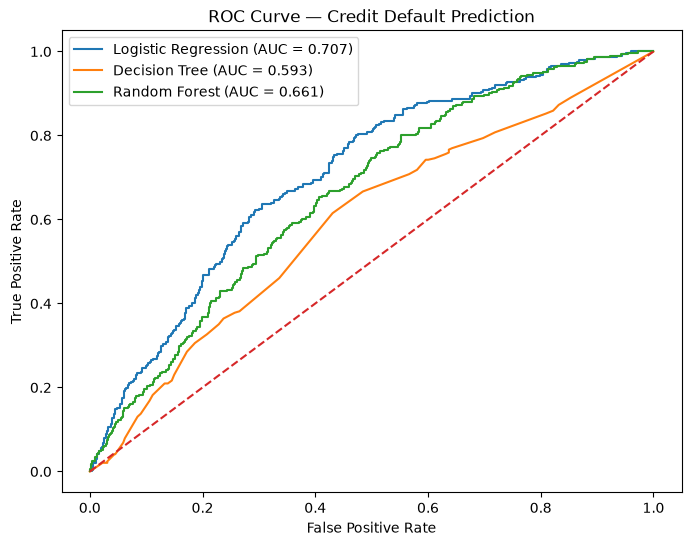

In [26]:
# Cell 26 — ROC curve

roc_data = [
    ("Logistic Regression", logistic_prob),
    ("Decision Tree", tree_prob),
    ("Random Forest", forest_prob)
]

plt.figure(figsize=(8, 6))

for name, probabilities in roc_data:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Credit Default Prediction")
plt.legend()
plt.show()


In [27]:
# Cell 27 — Random Forest feature importance

rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()
importances = rf_classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(feature_importance.head(15))


,Feature,Importance
82,numeric__CREDIT_SCORE,0.037735
4,numeric__R_DEBT_INCOME,0.024618
76,numeric__R_EXPENDITURE_DEBT,0.022980
26,numeric__R_FINES,0.021652
41,numeric__R_GROCERIES_DEBT,0.019724
47,numeric__R_HEALTH_DEBT,0.019123
58,numeric__R_TAX_DEBT,0.017727
70,numeric__R_UTILITIES_DEBT,0.016497
23,numeric__R_ENTERTAINMENT_DEBT,0.015179
20,numeric__R_ENTERTAINMENT,0.014389


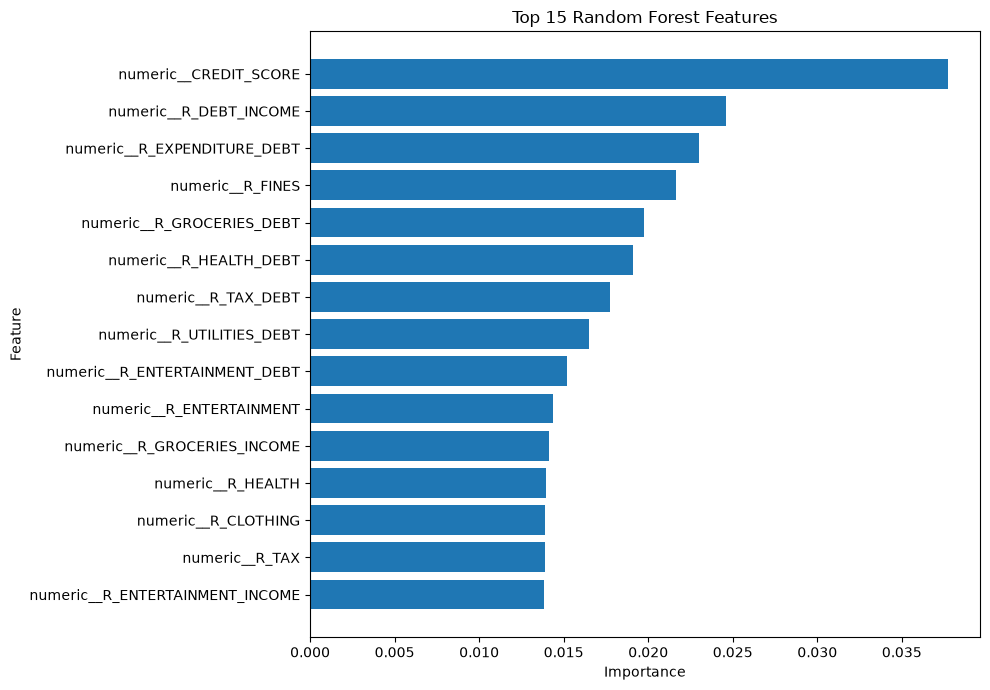

In [28]:
# Cell 28 — Plot top feature importance

top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Random Forest Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [29]:
# Cell 29 — Select and save the best model

model_map = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

# Select the best model using F1-Score first and ROC-AUC second.
best_model_name = results.iloc[0]["Model"]
best_model = model_map[best_model_name]

# Refit the selected model on the complete dataset before saving it for deployment.
best_model.fit(X, y)

MODEL_PATH = "../models/best_credit_default_model.pkl"
joblib.dump(best_model, MODEL_PATH)

print(f"Best model selected: {best_model_name}")
print("Selection criterion: highest F1-Score, then ROC-AUC.")
print(f"Deployment model saved to: {MODEL_PATH}")


Best model selected: Logistic Regression
Selection criterion: highest F1-Score, then ROC-AUC.
Deployment model saved to: ../models/best_credit_default_model.pkl


In [30]:
# Cell 30 — Save the model evaluation results

RESULTS_PATH = "../models/model_results.csv"
results.to_csv(RESULTS_PATH, index=False)

print(f"Results saved to: {RESULTS_PATH}")


Results saved to: ../models/model_results.csv


In [31]:
# Cell 31 — Load the saved model and verify it

loaded_model = joblib.load(MODEL_PATH)

loaded_predictions = loaded_model.predict(X_test)
loaded_probability = loaded_model.predict_proba(X_test)[:, 1]

print("Saved model loaded successfully.")
print("Verification on held-out test data:")
print("F1-score:", round(f1_score(y_test, loaded_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, loaded_probability), 4))


Saved model loaded successfully.
Verification on held-out test data:
F1-score: 0.5542
ROC-AUC: 0.7383


In [32]:
# Cell 32 — Example customer prediction

# This example uses one real row from the test set only to demonstrate
# the prediction workflow. Replace this dictionary with a new customer's
# feature values when making a real prediction.

sample_customer = X_test.iloc[[0]].copy()

prediction = loaded_model.predict(sample_customer)[0]
probability = loaded_model.predict_proba(sample_customer)[0, 1]

print("Predicted class:", int(prediction))
print("Probability of default:", round(float(probability), 4))

if prediction == 1:
    print("Prediction: HIGHER RISK / DEFAULT")
else:
    print("Prediction: LOWER RISK / NO DEFAULT")


Predicted class: 1
Probability of default: 0.6504
Prediction: HIGHER RISK / DEFAULT


In [33]:
# Cell 33 — Final project summary

print("PROJECT: Credit Default Prediction")
print("=" * 45)
print("Dataset rows:", len(df))
print("Original features:", df.shape[1] - 1)
print("Best model:", best_model_name)

best_row = results.iloc[0]
print("Accuracy :", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall   :", round(best_row["Recall"], 4))
print("F1-Score :", round(best_row["F1-Score"], 4))
print("ROC-AUC  :", round(best_row["ROC-AUC"], 4))

print("\nGoal: predict the probability/class of customer credit default")
print("using financial, spending, debt, savings and credit-related data.")


PROJECT: Credit Default Prediction
Dataset rows: 4995
Original features: 86
Best model: Logistic Regression
Accuracy : 0.6507
Precision: 0.435
Recall   : 0.6667
F1-Score : 0.5265
ROC-AUC  : 0.7071

Goal: predict the probability/class of customer credit default
using financial, spending, debt, savings and credit-related data.
